STEP 1. Orderbooks snapshots are persisted in redis by:

a. Periodic snapshots: https://github.com/r0bbar/siglab/blob/master/siglab_py/market_data_providers/aggregated_orderbook_provider.py

KEY format: 
    
    orderbooks:{TICKER}:{EXCHANGE_NAME}:{TIMESTAMP_MS}

By default, candle_size 1h. ttl_ms = 60 sec x 24 x 7 (i.e. 7 days).

b. Entries and Exits: https://github.com/r0bbar/siglab/blob/master/siglab_py/algo/strategy_executor.py

KEY format:

    orderbooks:{entry|exit}:{TICKER}:{EXCHANGE_NAME}:{TIMESTAMP_MS}

By default, param 'ob_ttl_ms' : 1000*60*60*24 *365 *5 (i.e. 5 years)

STEP 2. Pull orderbooks from redis to disk

https://github.com/r0bbar/siglab/blob/master/siglab_py/market_data_providers/archive_redis_ob.py

STEP 3. From orderbooks cached on disk, calculate order book features, and publish back to redis

https://github.com/r0bbar/siglab/blob/master/siglab_py/market_data_providers/process_archived_ob.py

STEP 4. Run this notebook for time-series visualisation

In [26]:
import json
import redis
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

In [27]:
TICKER = "SOL"
EXCHANGE = "binance"
PATTERN = f"orderbook-features:{TICKER}:{EXCHANGE}:*"

ob_feature_field : str = "spread_bps_by_order_notional"

In [28]:
r = redis.Redis(host="localhost", port=6379, db=0)

In [29]:
rows = []
for key in r.scan_iter(match=PATTERN, count=1000):
    raw = r.get(key)
    if raw is None:
        continue
    feat = json.loads(raw)
    ts_ms = feat.get("timestamp_ms") or int(key.decode().rsplit(":", 1)[-1])
    s = feat.get(ob_feature_field) # select feature field
    if s is None:
        continue
    rows.append((ts_ms, float(s)))

rows.sort(key=lambda x: x[0])
xs = [datetime.fromtimestamp(int(t) / 1000) for t, _ in rows]
ys = [v for _, v in rows]

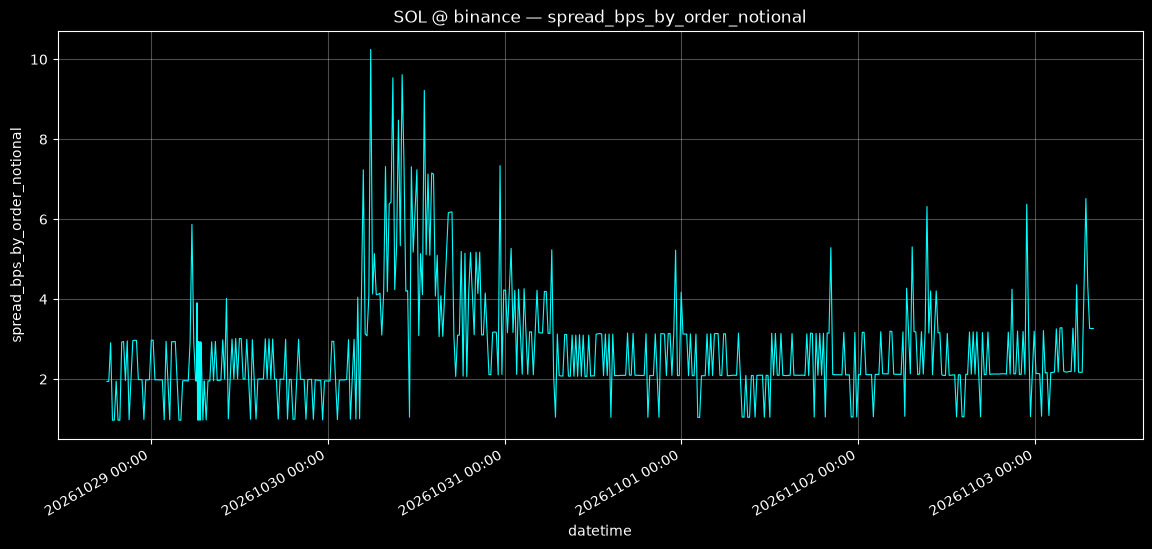

In [30]:
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(xs, ys, color="cyan", linewidth=0.8)
ax.set_xlabel("datetime")
ax.set_ylabel(ob_feature_field)
ax.set_title(f"{TICKER} @ {EXCHANGE} — {ob_feature_field}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y%m%d %H:%M"))
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()